# Drought indicators from monthly composites

**Question:** *Which fields are stressed this summer, how badly, and compared with what?*

Notebook 1 produced monthly median composites for the Marchfeld from Sentinel-2 and Landsat. Here we
turn them into drought information in two steps:

1. **Spectral indices** describe the surface in each composite: greenness, canopy water, heat.
2. **Drought indicators** compare each index with its own history for the same calendar month: anomalies,
   standardised anomalies (z-scores), condition indices (VCI, TCI, VHI) and the share of the area under
   stress.

| Index | Formula | Tells us | In drought |
|---|---|---|---|
| NDVI | (NIR − red) / (NIR + red) | green biomass | falls |
| EVI | 2.5 (NIR − red) / (NIR + 6 red − 7.5 blue + 1) | greenness, less saturation in dense crops | falls |
| NDMI | (NIR − SWIR1) / (NIR + SWIR1) | canopy water content | falls, often before NDVI |
| MSI | SWIR1 / NIR | moisture stress | rises |
| NDWI | (green − NIR) / (green + NIR) | open water, wet surfaces | not a vegetation index |
| LST | Landsat thermal band | surface temperature, evaporative cooling | rises |

In [9]:
import sys
import warnings
from pathlib import Path

# make the course helper package importable from any sub-folder
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "droughtkit").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import droughtkit as dk
from droughtkit import plotting as dkp

dkp.use_style()
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.float_format", "{:.2f}".format)

In [10]:
from droughtkit import maps as dkm
from droughtkit import remote_sensing as rs
from droughtkit import sample as sm

TARGET = "2026-07-01"          # month to map
BASELINE = (2017, 2025)        # reference years for the same calendar month

f_s2 = ROOT / "data" / "s2_marchfeld_monthly.nc"
f_ls = ROOT / "data" / "landsat_marchfeld_monthly.nc"
if f_s2.exists():
    s2 = xr.open_dataset(f_s2).load()
    ls = xr.open_dataset(f_ls).load() if f_ls.exists() else None
else:
    s2 = sm.sample_composites()
    ls = sm.sample_landsat(s2)
SRC = s2.attrs.get("source", "")
print(SRC)
idx = dk.spectral_indices(s2)

Copernicus Sentinel-2 L2A via Microsoft Planetary Computer, monthly median composites


## The indices in one month

July is peak season for maize, sugar beet and vegetables; winter cereals are already harvested. Each index
highlights something different, so look at them together.

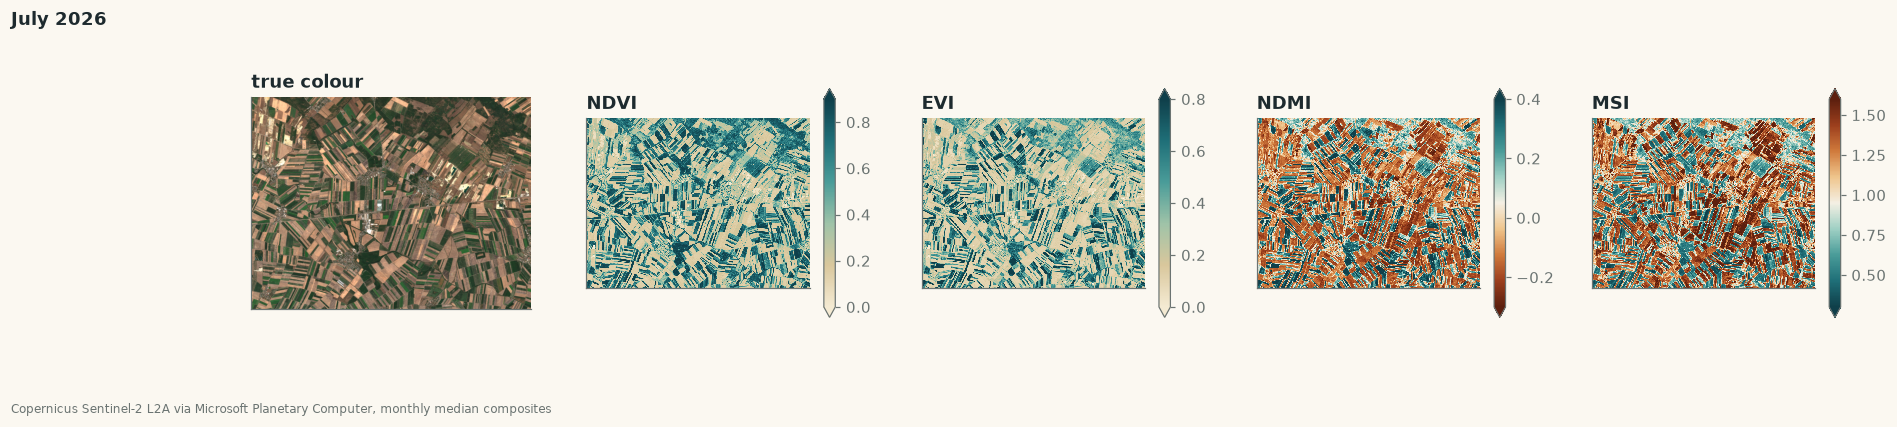

In [11]:
month = idx.sel(time=TARGET)
fig, ax = plt.subplots(1, 5, figsize=(19, 3.6))
ax[0].imshow(rs.rgb(s2.sel(time=TARGET)), extent=[s2.x.min(), s2.x.max(), s2.y.min(), s2.y.max()])
ax[0].set_title("true colour")
spec = [("NDVI", dkp.SAND_TEAL, 0, 0.9), ("EVI", dkp.SAND_TEAL, 0, 0.8),
        ("NDMI", dkp.DRY_WET, -0.3, 0.4), ("MSI", dkp.DRY_WET.reversed(), 0.3, 1.6)]
for a, (name, cmap, lo, hi) in zip(ax[1:], spec):
    month[name].plot(ax=a, cmap=cmap, vmin=lo, vmax=hi, cbar_kwargs={"shrink": 0.75, "label": ""})
    a.set_title(name)
for a in ax:
    a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([]); a.set_xlabel(""); a.set_ylabel(""); a.grid(False)
fig.suptitle(pd.Timestamp(TARGET).strftime("%B %Y"), x=0.01, ha="left", fontweight="bold")
dkp.source_note(fig, SRC)

## The seasonal cycle comes first

An NDVI of 0.3 in July means something very different for a harvested wheat field and a maize field. The
seasonal cycle of the area of interest (AOI) shows what is normal for each month. The shaded band is the
range of the reference years, the line is 2026.

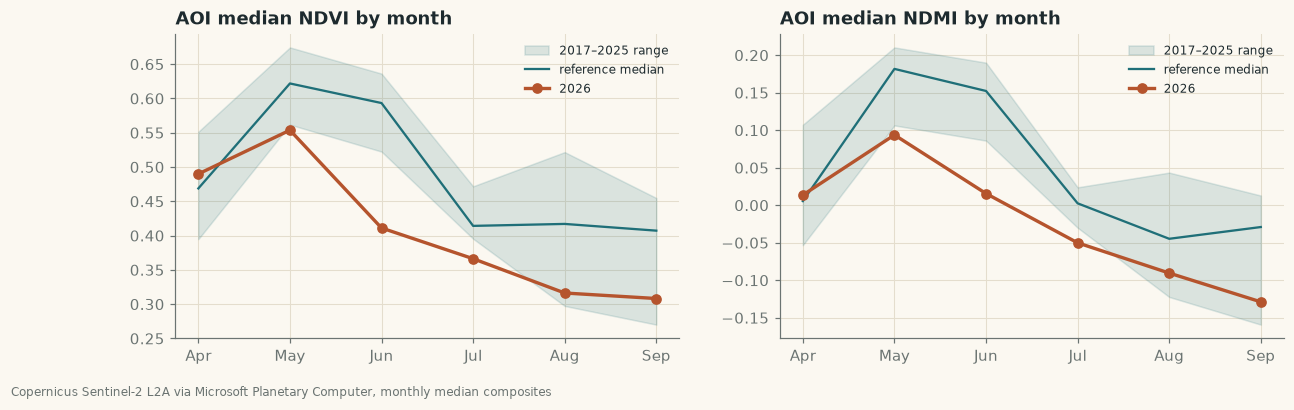

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a, name in zip(ax, ["NDVI", "NDMI"]):
    series = rs.aoi_median(idx[name])
    table = series.groupby([series.index.year, series.index.month]).first().unstack()
    ref = table.loc[BASELINE[0]:BASELINE[1]]
    m = table.columns
    a.fill_between(m, ref.min(), ref.max(), color=dkp.WET, alpha=0.15, label=f"{BASELINE[0]}–{BASELINE[1]} range")
    a.plot(m, ref.median(), color=dkp.WET, lw=1.5, label="reference median")
    if 2026 in table.index:
        a.plot(m, table.loc[2026], "o-", color=dkp.DRY, lw=2.2, label="2026")
    a.set_xticks(m, [pd.Timestamp(2000, k, 1).strftime("%b") for k in m])
    a.set_title(f"AOI median {name} by month"); a.legend(fontsize=8)
dkp.source_note(fig, SRC)

## Anomalies and z-scores: compared with the same month

The **anomaly** is the difference from the median of the same calendar month in the reference years. The
**standardised anomaly** (z-score) divides that difference by the year-to-year standard deviation, so a
−2 means "unusually low for this pixel and this month", whether the pixel is a forest or a sugar-beet field.

With nine reference years, a z-score is a rough guide rather than a probability. Sentinel-2's short record
is the main limitation, which is why notebook 3 uses MODIS for long baselines.

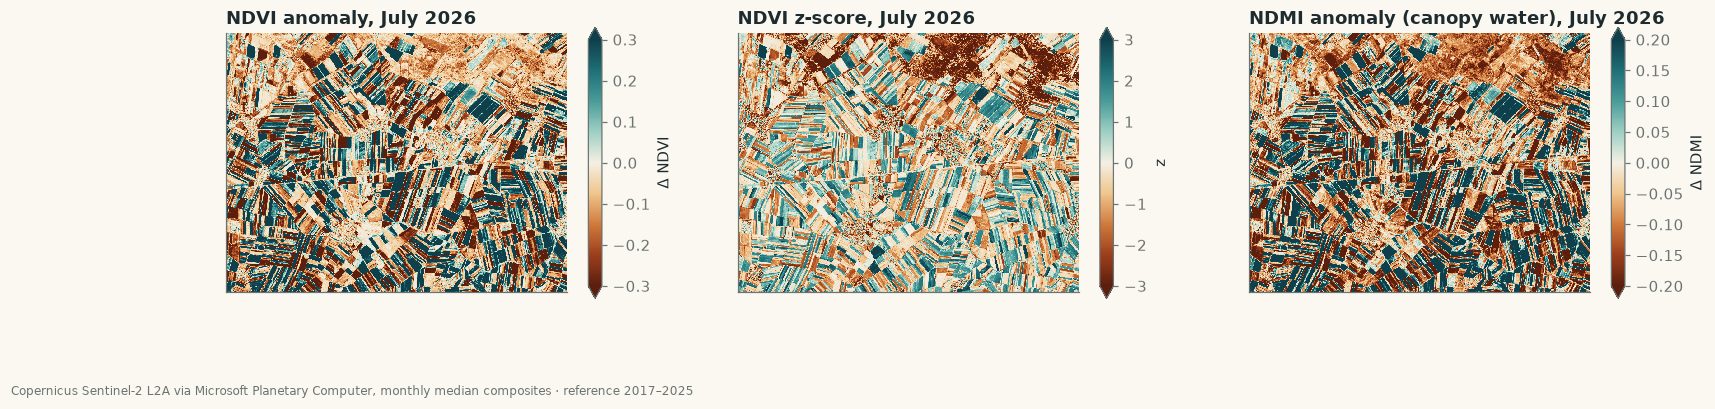

In [13]:
nd_anom = dk.anomaly(idx.NDVI, BASELINE)
nd_z = dk.anomaly(idx.NDVI, BASELINE, standardize=True)
nm_anom = dk.anomaly(idx.NDMI, BASELINE)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
nd_anom.sel(time=TARGET).plot(ax=ax[0], cmap=dkp.DRY_WET, vmin=-0.3, vmax=0.3,
                              cbar_kwargs={"label": "Δ NDVI", "shrink": 0.8})
nd_z.sel(time=TARGET).plot(ax=ax[1], cmap=dkp.DRY_WET, vmin=-3, vmax=3,
                           cbar_kwargs={"label": "z", "shrink": 0.8})
nm_anom.sel(time=TARGET).plot(ax=ax[2], cmap=dkp.DRY_WET, vmin=-0.2, vmax=0.2,
                              cbar_kwargs={"label": "Δ NDMI", "shrink": 0.8})
for a, t in zip(ax, ["NDVI anomaly", "NDVI z-score", "NDMI anomaly (canopy water)"]):
    a.set_title(f"{t}, {pd.Timestamp(TARGET):%B %Y}")
    a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([]); a.set_xlabel(""); a.set_ylabel(""); a.grid(False)
dkp.source_note(fig, f"{SRC} · reference {BASELINE[0]}–{BASELINE[1]}")

**Reading the maps.** The field pattern is the point: in a dry summer, rainfed parcels drop well below
their usual July values while irrigated parcels stay close to normal or even above it. Before calling a
brown field a drought field, check the crop: a harvested cereal field in July is normal. The INVEKOS field
parcels published by AMA on [data.gv.at](https://www.data.gv.at) give the crop of every field and turn this
into a per-crop analysis.

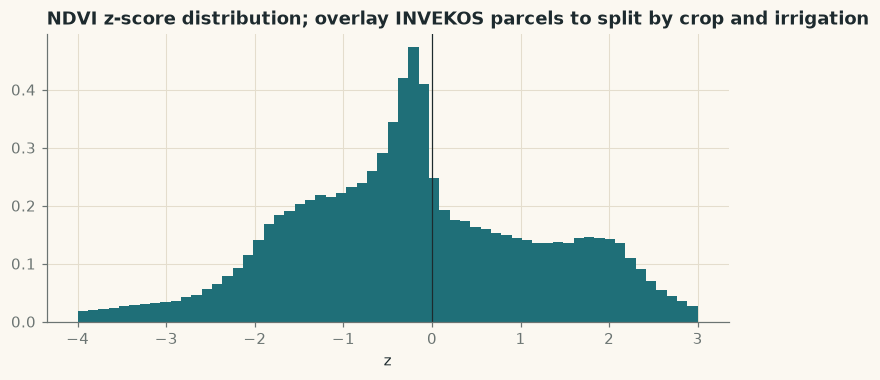

In [14]:
par = sm.sample_parcels() if "synthetic" in SRC else None
z = nd_z.sel(time=TARGET)
fig, ax = plt.subplots(figsize=(8, 3.4))
if par is not None:
    arable = (par.crop < 5).values
    for mask, label, color in [(arable & ~par.irrigated.values, "rainfed fields", dkp.DRY),
                               (arable & par.irrigated.values, "irrigated fields", dkp.WET)]:
        ax.hist(z.values[mask], bins=60, range=(-4, 3), alpha=0.6, color=color, label=label, density=True)
    ax.legend()
    ax.set_title("NDVI z-score, July 2026: rainfed vs irrigated (synthetic parcels)")
else:
    ax.hist(z.values.ravel(), bins=60, range=(-4, 3), color=dkp.WET, density=True)
    ax.set_title("NDVI z-score distribution; overlay INVEKOS parcels to split by crop and irrigation")
ax.axvline(0, color=dkp.INK, lw=0.8); ax.set_xlabel("z");

## Condition indices and surface temperature

The **Vegetation Condition Index** places each month between the lowest (0) and highest (100) value of the
same month in the record. The **Temperature Condition Index** does the same for land-surface temperature,
inverted so that 0 is the hottest. Their average, the **Vegetation Health Index**, combines a slow greenness
signal with a fast thermal one (Kogan 1995).

$$\mathrm{VCI} = 100\,\frac{\mathrm{NDVI}-\mathrm{NDVI}_{\min,m}}{\mathrm{NDVI}_{\max,m}-\mathrm{NDVI}_{\min,m}}\qquad
\mathrm{TCI} = 100\,\frac{\mathrm{LST}_{\max,m}-\mathrm{LST}}{\mathrm{LST}_{\max,m}-\mathrm{LST}_{\min,m}}\qquad
\mathrm{VHI} = \tfrac12(\mathrm{VCI}+\mathrm{TCI})$$

Here LST comes from Landsat. With a ten-year record the minimum and maximum are unstable, so read these maps
as relative patterns, not as calibrated classes.

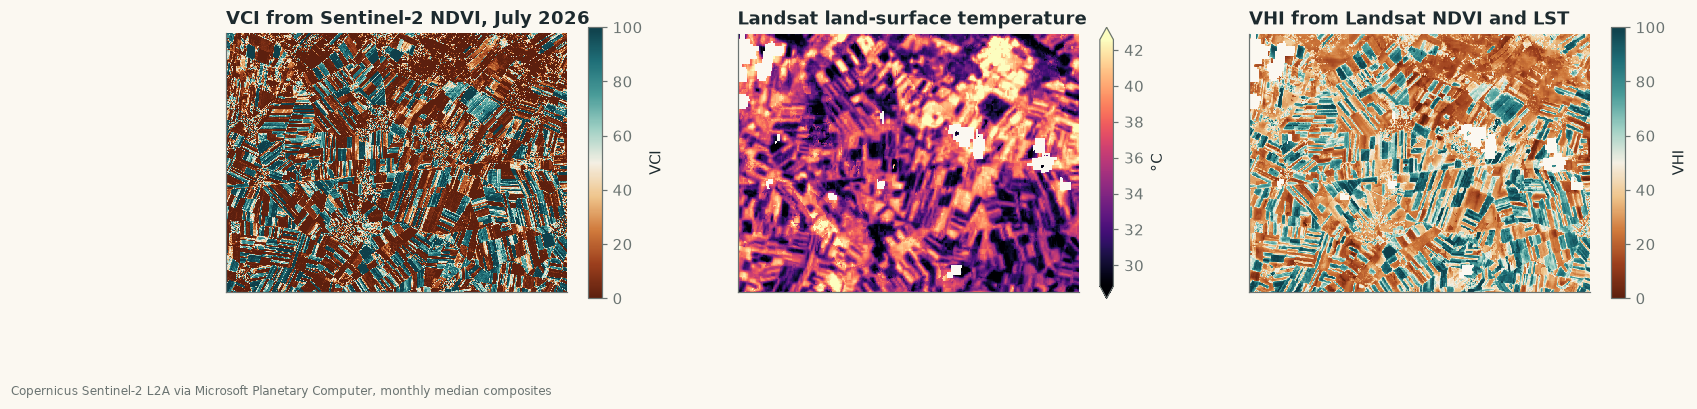

In [15]:
vci = dk.vci(idx.NDVI, BASELINE, min_years=5)
lst = ls.lst if ls is not None and "lst" in ls else None
fig, ax = plt.subplots(1, 3 if lst is not None else 1, figsize=(17, 4), squeeze=False)
ax = ax[0]
vci.sel(time=TARGET).plot(ax=ax[0], cmap=dkp.DRY_WET, vmin=0, vmax=100, cbar_kwargs={"label": "VCI", "shrink": 0.8})
ax[0].set_title(f"VCI from Sentinel-2 NDVI, {pd.Timestamp(TARGET):%B %Y}")
if lst is not None:
    lst_t = lst.sel(time=TARGET)
    lst_t.plot(ax=ax[1], cmap="magma", robust=True, cbar_kwargs={"label": "°C", "shrink": 0.8})
    ax[1].set_title("Landsat land-surface temperature")
    tci = dk.tci(lst, BASELINE, min_years=5)
    vhi_ls = dk.vhi(dk.vci(dk.spectral_indices(ls).NDVI if "blue" in ls else (ls.nir - ls.red) / (ls.nir + ls.red),
                           BASELINE), tci)
    vhi_ls.sel(time=TARGET).plot(ax=ax[2], cmap=dkp.DRY_WET, vmin=0, vmax=100,
                                 cbar_kwargs={"label": "VHI", "shrink": 0.8})
    ax[2].set_title("VHI from Landsat NDVI and LST")
for a in ax:
    a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([]); a.set_xlabel(""); a.set_ylabel(""); a.grid(False)
dkp.source_note(fig, SRC)

## How much of the area is under stress?

A map shows where; a time series shows when and how much. The share of the AOI with an NDVI z-score below
−1 per month summarises each season in one line, and makes 2026 directly comparable with earlier years.

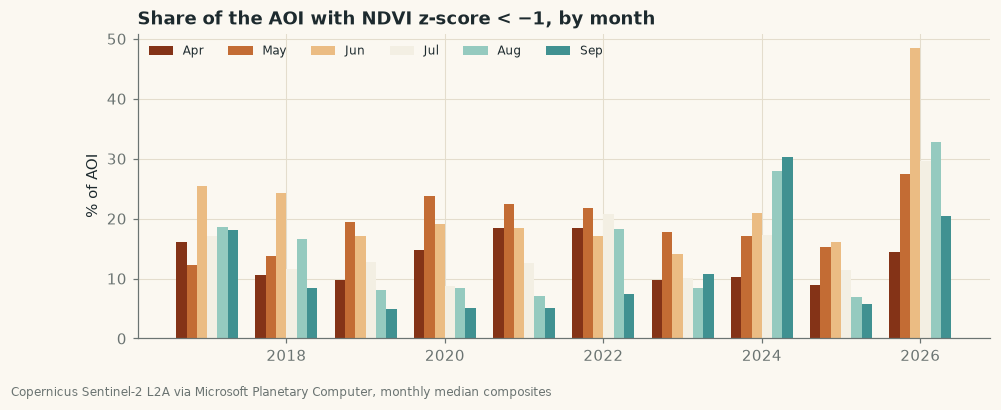

In [16]:
share = dk.area_below(nd_z, -1.0)
tab = share.groupby([share.index.year, share.index.month]).first().unstack()
fig, ax = plt.subplots(figsize=(10, 3.6))
width = 0.13
for k, m in enumerate(tab.columns):
    ax.bar(tab.index + (k - 2.5) * width, tab[m], width=width, color=dkp.DRY_WET(0.08 + 0.14 * k),
           label=pd.Timestamp(2000, m, 1).strftime("%b"))
ax.set(ylabel="% of AOI", title="Share of the AOI with NDVI z-score < −1, by month")
ax.legend(ncol=6, fontsize=8, loc="upper left")
dkp.source_note(fig, SRC)

## Before you call it drought

- Same month, same sensor processing, a reference period you report.
- Pixel mask applied, coverage checked, months without clear observations left empty.
- Crop calendar and crop type considered (harvest, mowing, rotation, irrigation).
- Several indices agree: greenness (NDVI, EVI), water (NDMI, MSI) and heat (LST).
- The pattern is consistent with the weather: notebook 3 adds ERA5 SPI and SPEI as climate context.

## Exercises

1. Map the NDVI z-score for May 2026. Which fields were already stressed in spring?
2. Compare NDVI and NDMI anomalies field by field. Which responds first, and in which crops?
3. Change `BASELINE` to (2019, 2025). How sensitive are the z-scores to the reference years?
4. Compute `dk.area_below(nd_z, -1.5)` and `-2`. How does the picture of 2026 change?
5. (Online) Download INVEKOS parcels for the AOI, rasterise the crop codes onto the composite grid, and
   compute the median NDVI z-score per crop.